In [5]:
from IPython.display import clear_output, display
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
import seaborn as sns
import torch
from ipywidgets import Dropdown, FloatSlider, HBox, VBox, Output

from era_data import TabletPeriodDataset, get_IDS
from VAE_model_tablets_class import VAE
from visualization_funcs import generate_image_from_VAE

warnings.filterwarnings("ignore", category=FutureWarning)

In [6]:
"""
Download trained VAE model from Zenodo if not already present.
DOI: 10.5281/zenodo.11668219  (record 11668220)
Contains: VAE checkpoint + class_weights_period.pt
"""
import os, zipfile, urllib.request

VAE_ZIP_URL = 'https://zenodo.org/api/records/11668220/files/VAE_trained_model.zip/content'
VAE_ZIP_LOCAL = 'VAE_trained_model.zip'

# Check whether the checkpoint already exists (any .ckpt under lightning_logs)
import glob as _glob
ckpt_exists = bool(_glob.glob('lightning_logs/**/*.ckpt', recursive=True))
weights_exists = os.path.exists('data/class_weights_period.pt')

if not ckpt_exists or not weights_exists:
    if not os.path.exists(VAE_ZIP_LOCAL):
        print(f'Downloading VAE_trained_model.zip from Zenodo (~87 MB)...')
        urllib.request.urlretrieve(VAE_ZIP_URL, VAE_ZIP_LOCAL)
        print('Download complete.')
    print('Extracting...')
    with zipfile.ZipFile(VAE_ZIP_LOCAL, 'r') as z:
        z.extractall('.')
    print('Extraction complete.')
    print('Files extracted:')
    for f in _glob.glob('lightning_logs/**/*.ckpt', recursive=True):
        print(f'  {f}')
    if os.path.exists('data/class_weights_period.pt'):
        print('  data/class_weights_period.pt')
else:
    print('VAE model files already present — skipping download.')

Extracting...
Extraction complete.
Files extracted:


# Hyperparameters

In [7]:
IMG_DIR = 'output/images_preprocessed'
VERSION_NAME ='period_clf_bs8_lr0.0001_beta_1_epochs_30-VAE-94936_samples-masked_w_classification_loss-equalpartsloss-April16_2'
IDS = get_IDS(IMG_DIR=IMG_DIR)
print(len(IDS))

0


In [8]:
num_classes = len(TabletPeriodDataset.PERIOD_INDICES)

# class_weights_period.pt is not included in the Zenodo model zip.
# The weights only affect the classification loss during training;
# they have no effect on the decoder used for latent-space traversal.
try:
    class_weights = torch.load("data/class_weights_period.pt")
    print("Loaded class_weights from data/class_weights_period.pt")
except FileNotFoundError:
    class_weights = torch.ones(num_classes)
    print(f"class_weights_period.pt not found — using uniform weights ({num_classes} classes).")
    print("This is correct for traversal: weights only affect training loss, not the decoder.")

class_weights_period.pt not found — using uniform weights (22 classes).
This is correct for traversal: weights only affect training loss, not the decoder.


In [9]:
import os, urllib.request

ZENODO_BASE = 'https://zenodo.org/records/12787746/files'

def load_encoding_csv(split):
    local = f'vae_encodings_and_data/vae_encoding_df_April16_w_class_{split}.csv'
    if os.path.exists(local):
        return pd.read_csv(local)
    url = f'{ZENODO_BASE}/vae_encoding_df_April16_w_class_{split}.csv'
    print(f'Downloading {split} encodings from Zenodo...')
    return pd.read_csv(url)

df_encodings_train = load_encoding_csv('train')
df_encodings_test  = load_encoding_csv('test')
print(f"Train: {len(df_encodings_train):,} rows | Test: {len(df_encodings_test):,} rows")

Train: 74,300 rows | Test: 9,297 rows


# Load Model

In [10]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'

In [11]:
# Checkpoint extracted from Zenodo zip into VAE_trained_model/
# (notebook originally expected lightning_logs/ which is the GPU server path)
import glob as _glob

def find_checkpoint(version_name):
    """Search common locations for the checkpoint file."""
    candidates = [
        f'lightning_logs/{version_name}/checkpoints/epoch=22-step=213621.ckpt',
        f'VAE_trained_model/{version_name}/checkpoints/epoch=22-step=213621.ckpt',
    ]
    for path in candidates:
        if os.path.exists(path):
            return path
    # Fallback: find any .ckpt under VAE_trained_model or lightning_logs
    found = (_glob.glob('VAE_trained_model/**/*.ckpt', recursive=True) +
             _glob.glob('lightning_logs/**/*.ckpt', recursive=True))
    if found:
        return found[0]
    raise FileNotFoundError("No .ckpt file found. Run the download cell above first.")

checkpoint_path = find_checkpoint(VERSION_NAME)
print(f"Using checkpoint: {checkpoint_path}")

vae_model = VAE.load_from_checkpoint(
    checkpoint_path,
    image_channels=1, z_dim=12, lr=0.0001,
    use_classification_loss=True, num_classes=num_classes,
    loss_type="weighted", class_weights=class_weights, device=device
)

Using checkpoint: VAE_trained_model/period_clf_bs8_lr0.0001_beta_1_epochs_30-VAE-94936_samples-masked_w_classification_loss-equalpartsloss-April16_2/checkpoints/epoch=22-step=213621.ckpt


/Users/shaigordin/Dropbox/Git-projects/ShapingHistory/VAE_model_tablets_class.py:75: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.class_weights = torch.tensor(class_weights).to(device)


# Plot entries boxplots

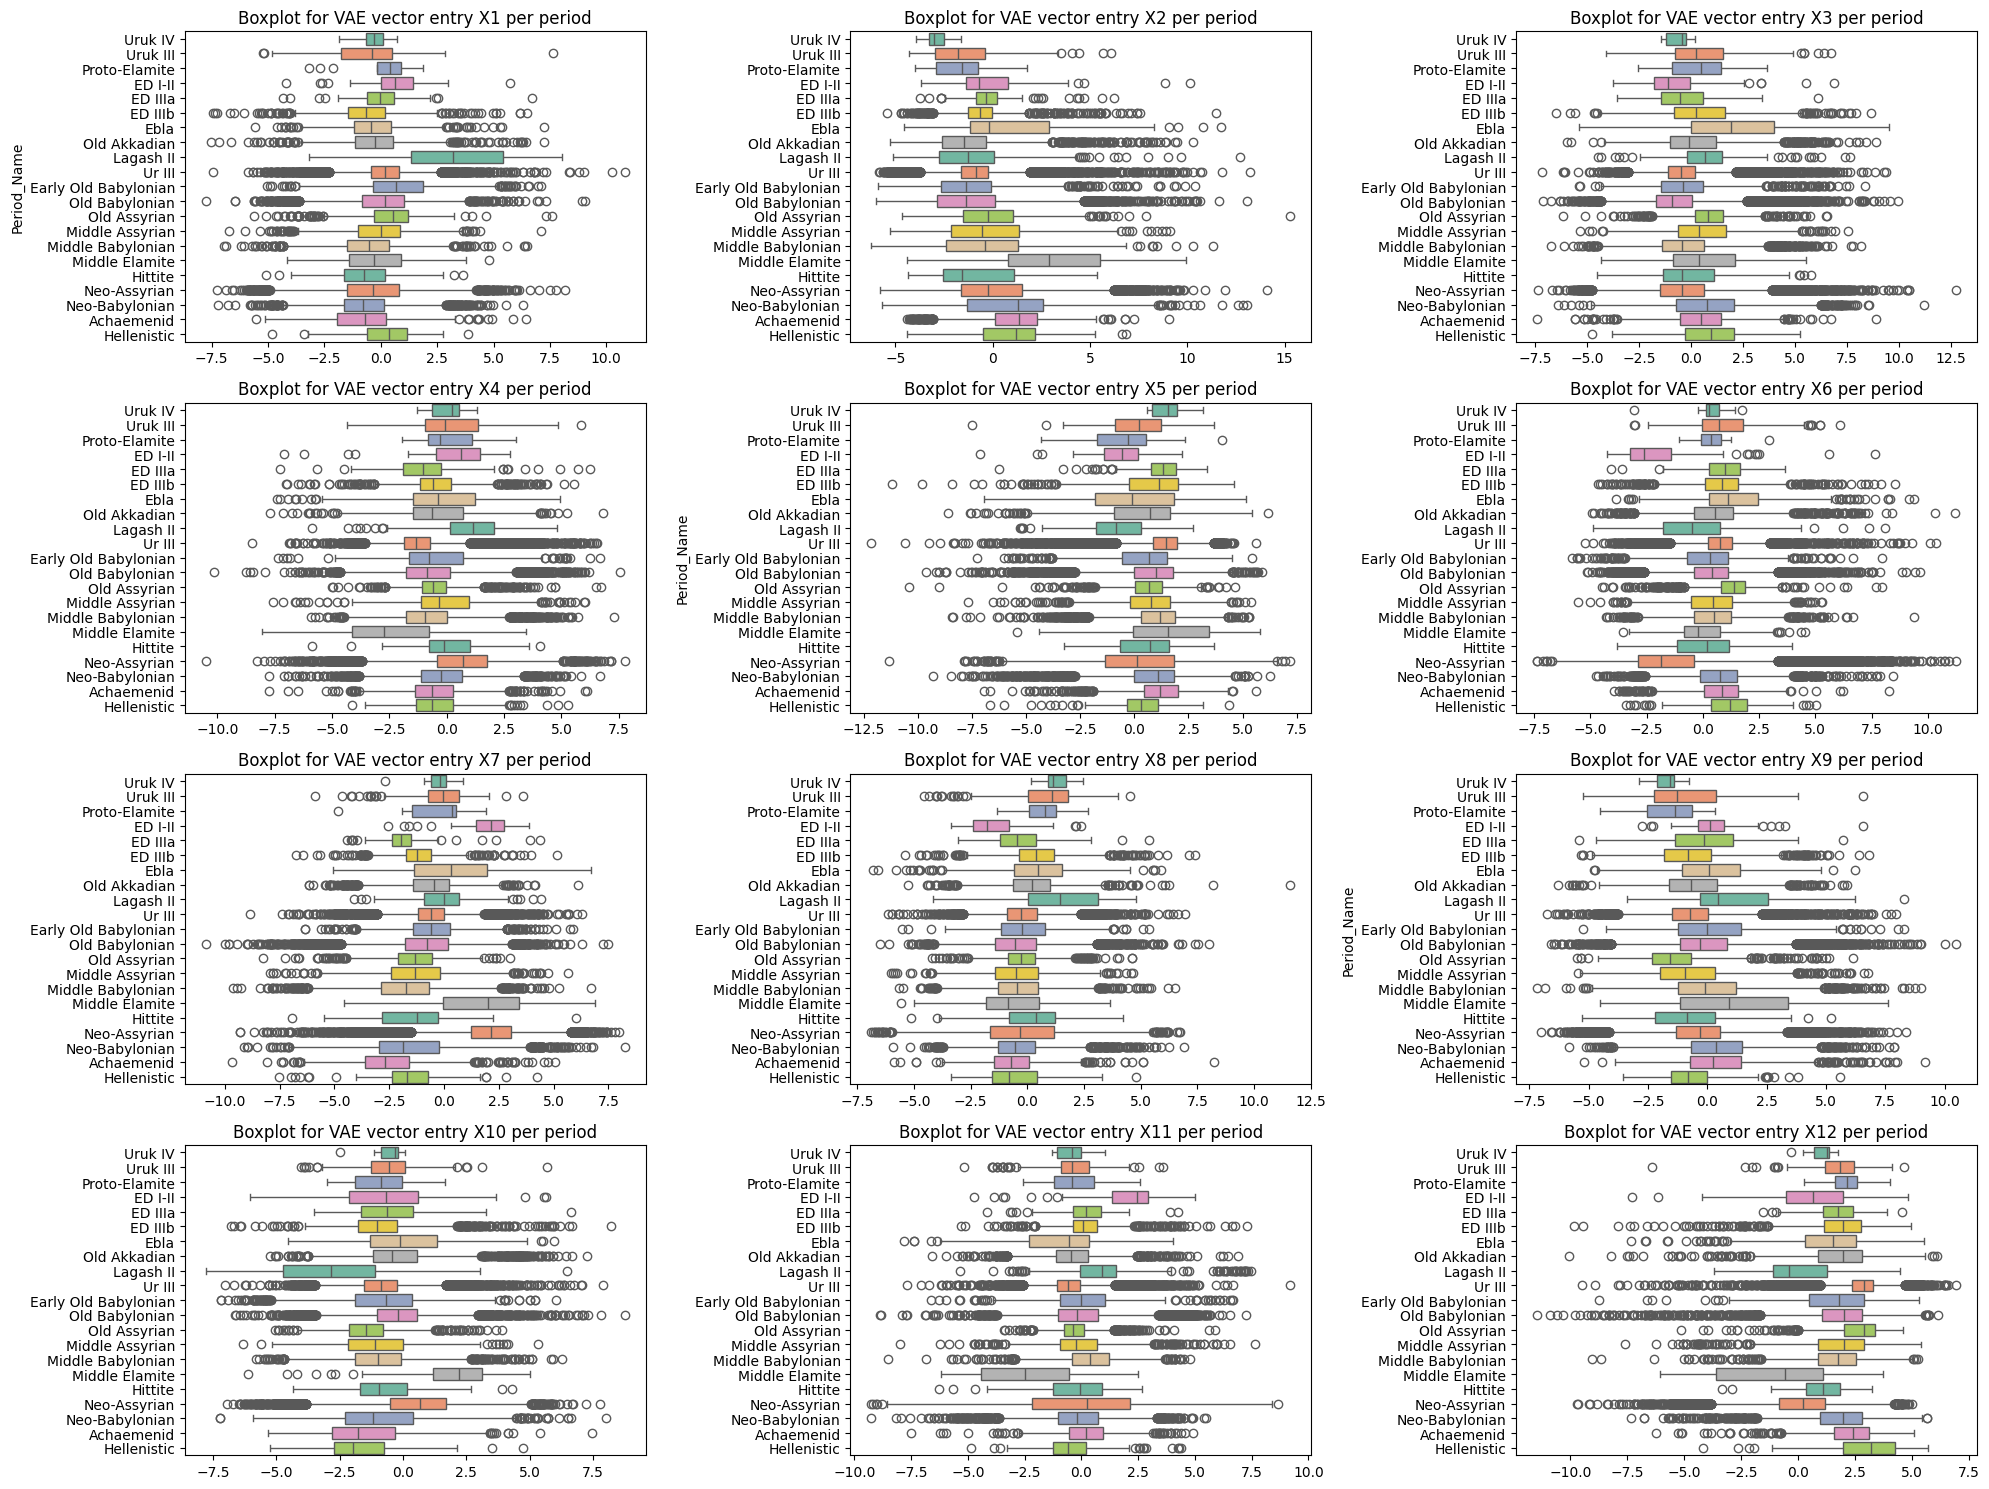

In [12]:
period_order = ['Uruk IV', 'Uruk III', 'Proto-Elamite', 'ED I-II', 'ED IIIa', 'ED IIIb', 'Ebla', 'Old Akkadian', 'Lagash II', 
                'Ur III', 'Early Old Babylonian', 'Old Babylonian', 'Old Assyrian', 'Middle Assyrian', 
                'Middle Babylonian', 'Middle Elamite', 'Hittite', 'Neo-Assyrian', 
                'Neo-Babylonian', 'Achaemenid', 'Hellenistic']

palette = 'Set2'  
fig, axes = plt.subplots(nrows=4, ncols=3, figsize=(20, 15))  # Adjust figsize as needed
axes = axes.flatten()  

for i, col in enumerate([f'X{i}' for i in range(1, 13)]):
    sns.boxplot(x=col, y='Period_Name', data=df_encodings_train, order=period_order, ax=axes[i], palette=palette)
    axes[i].set_title(f'Boxplot for VAE vector entry {col} per period')
    axes[i].tick_params(labelsize=10)  # Adjust label size for better readability
    if i < 12:  
        axes[i].set_xlabel('')
    if i % 4 != 0: 
        axes[i].set_ylabel('')

plt.tight_layout()  
plt.show()

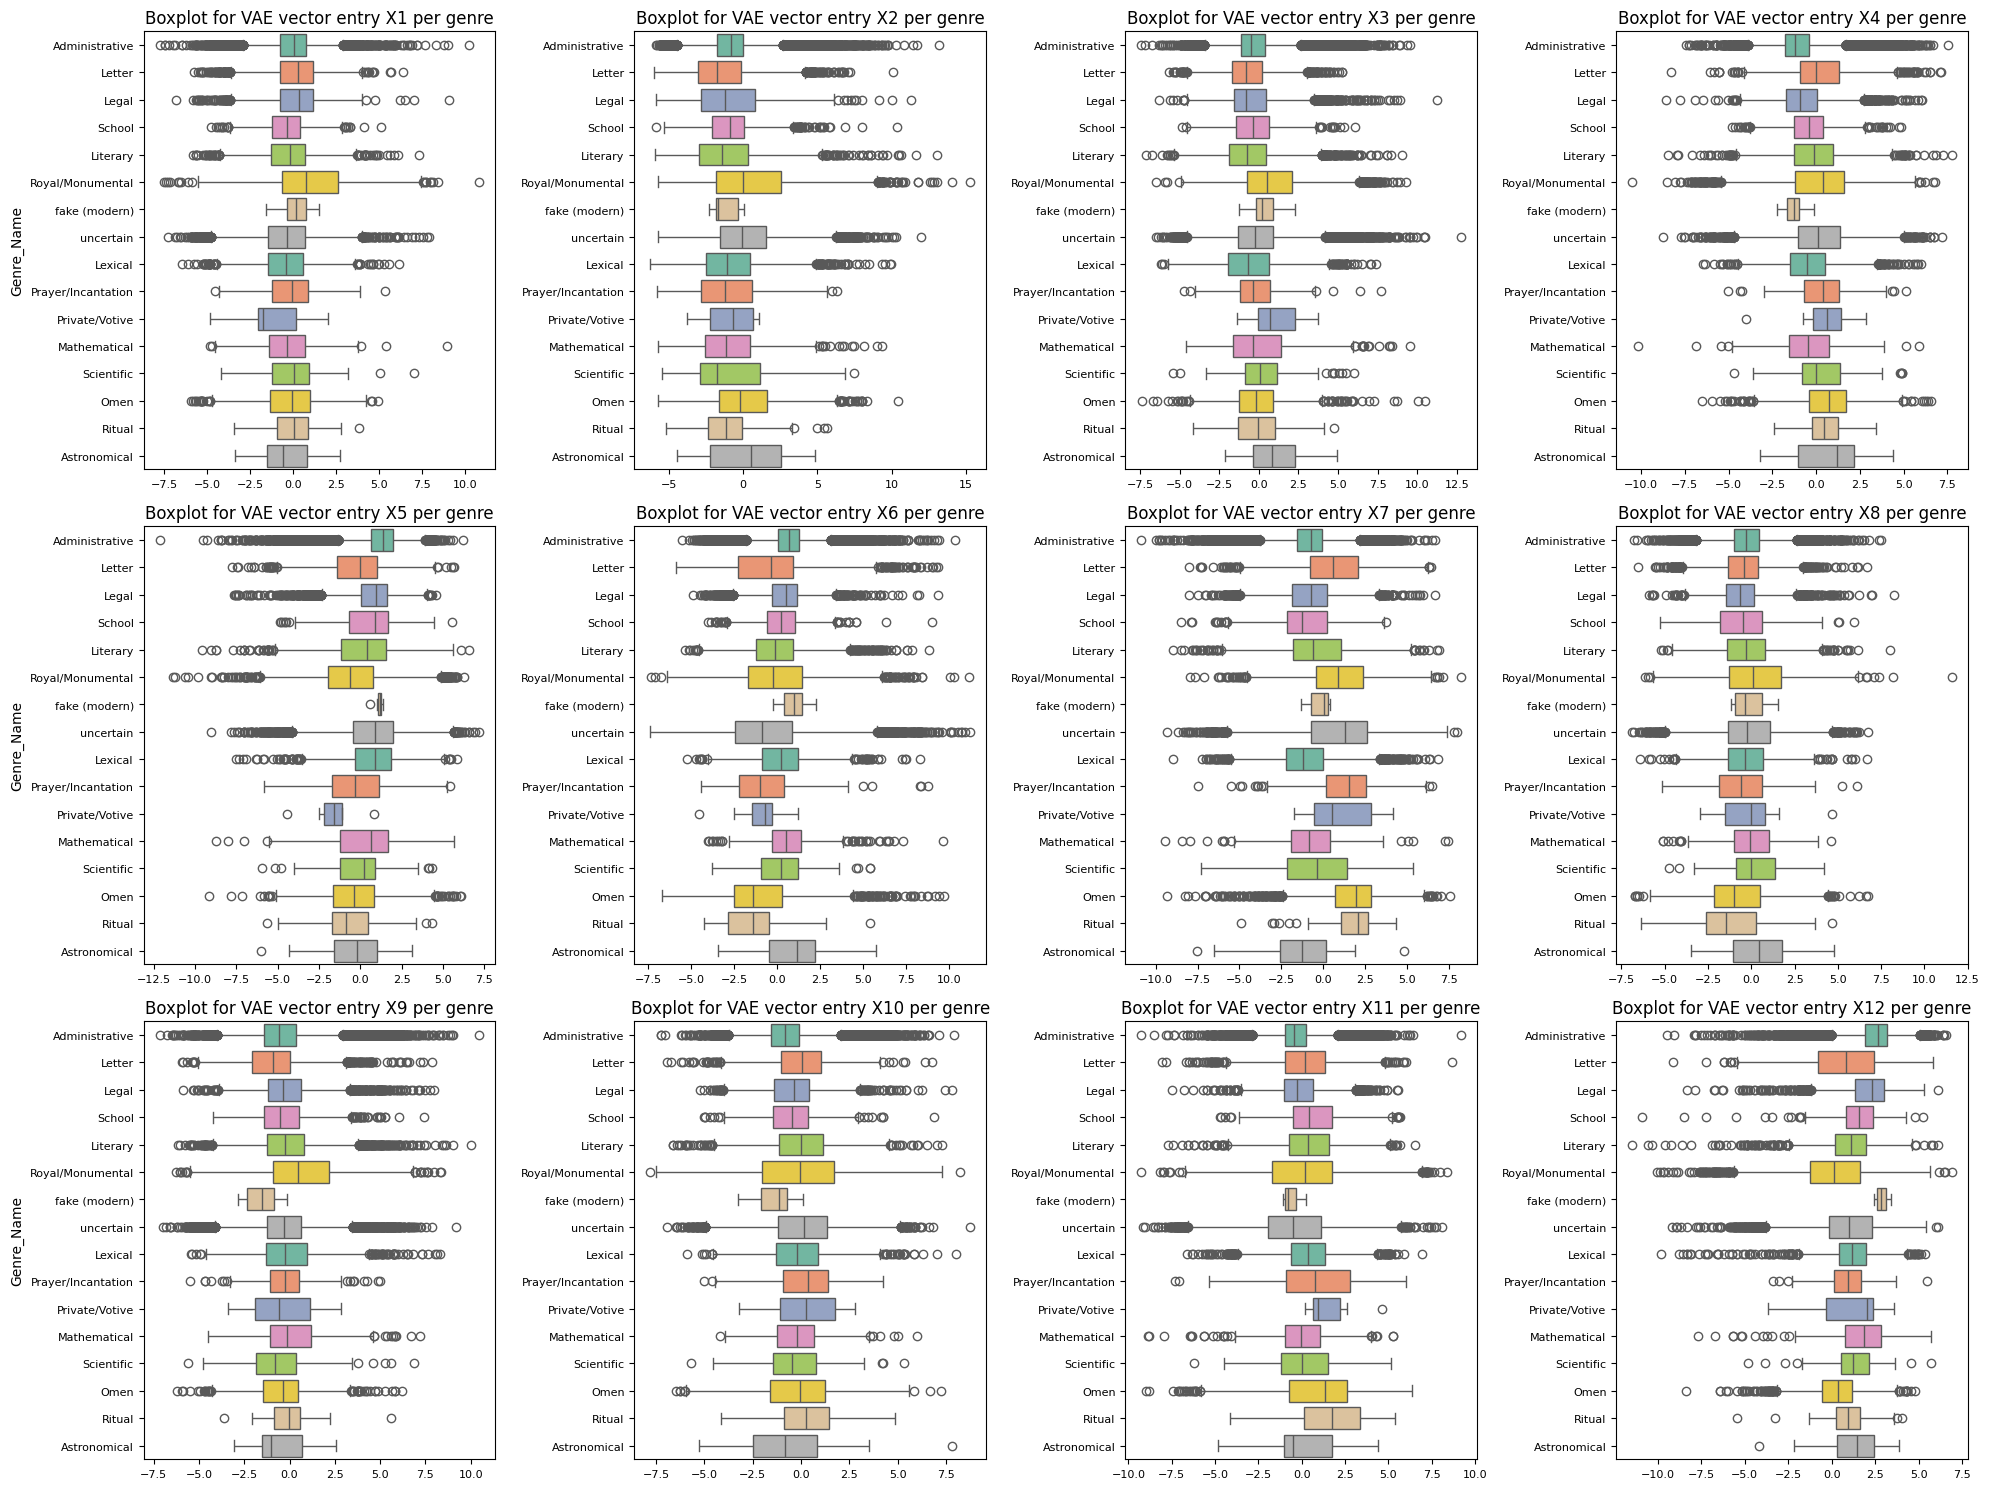

In [13]:
fig, axes = plt.subplots(nrows=3, ncols=4, figsize=(20, 15)) 
axes = axes.flatten()  

for i, col in enumerate([f'X{i}' for i in range(1, 13)]):
    sns.boxplot(x=col, y='Genre_Name', data=df_encodings_train, ax=axes[i], palette=palette)
    axes[i].set_title(f'Boxplot for VAE vector entry {col} per genre')
    axes[i].tick_params(labelsize=8) 
    if i < 12:  
        axes[i].set_xlabel('')
    if i % 4 != 0: 
        axes[i].set_ylabel('')

plt.tight_layout()  
plt.show()

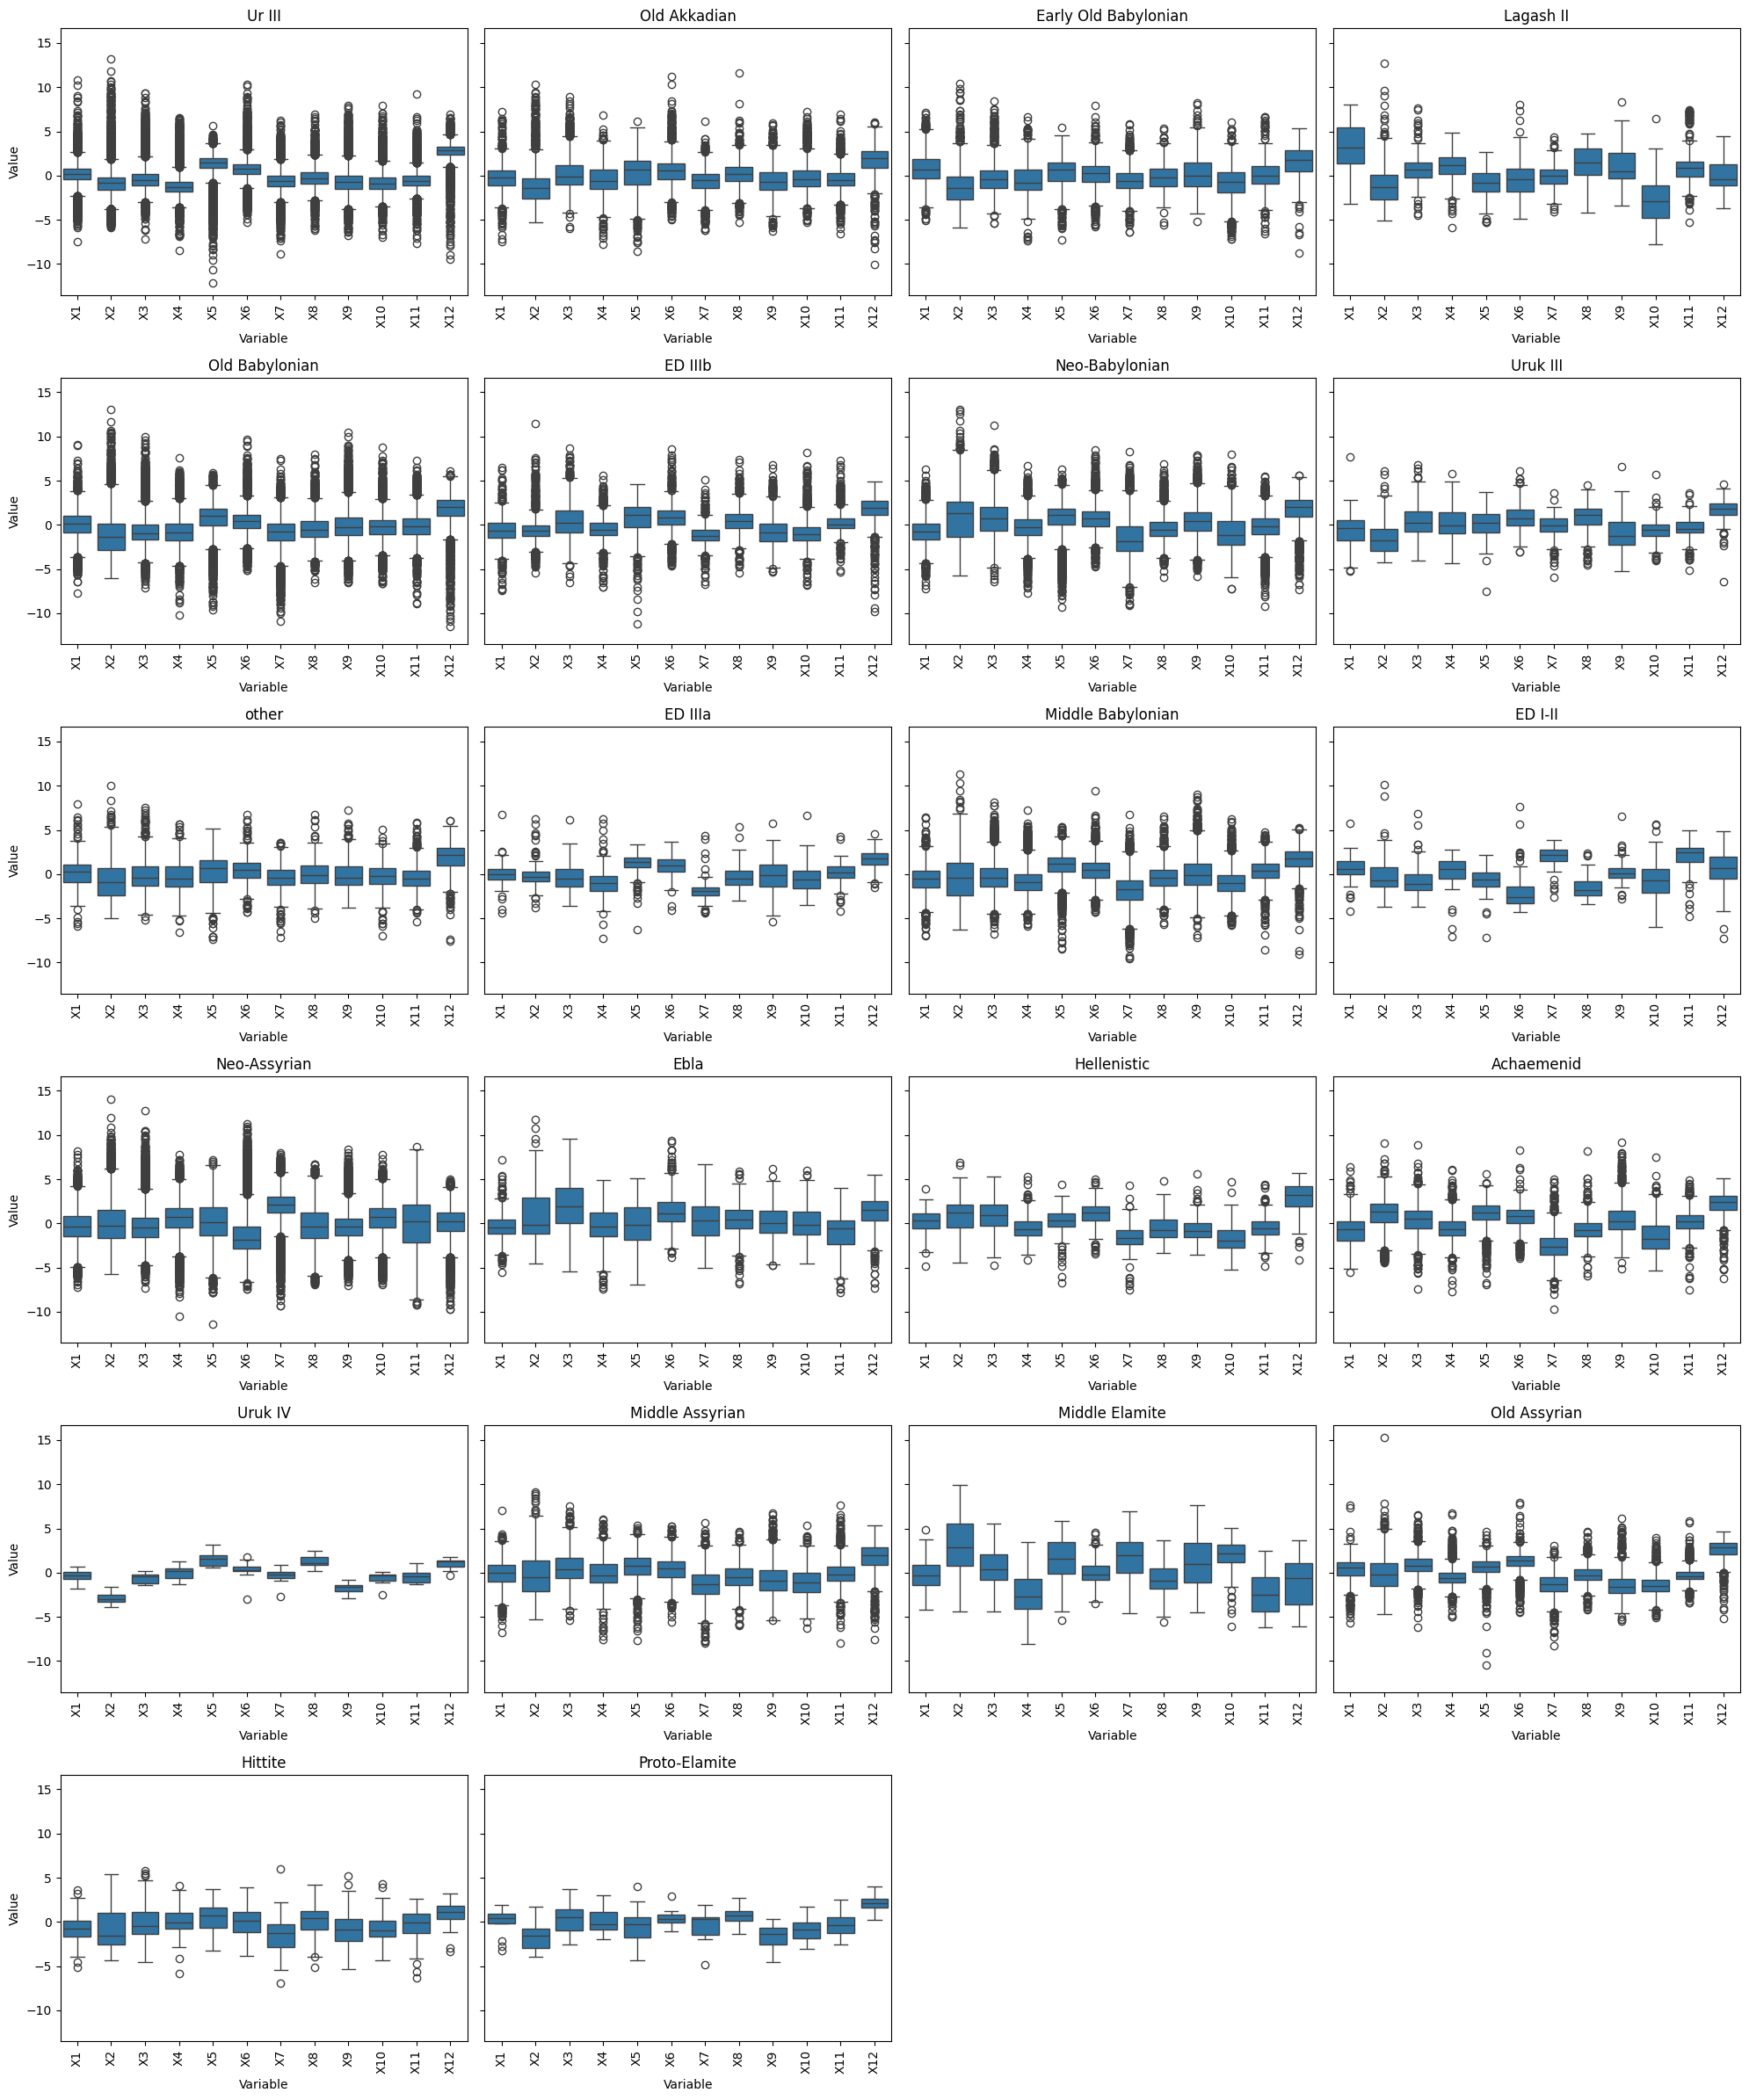

In [14]:
melted_df = df_encodings_train.melt(id_vars='Period_Name', value_vars=[f'X{i}' for i in range(1, 13)],
                                    var_name='Variable', value_name='Value')

n_cols = 4
n_rows = -(-22 // n_cols)

fig, axes = plt.subplots(nrows=n_rows, ncols=n_cols, figsize=(20, 4*n_rows), sharey=True) 
axes = axes.flatten()  

for i, period in enumerate(melted_df['Period_Name'].unique()):
    sns.boxplot(x='Variable', y='Value', data=melted_df[melted_df['Period_Name'] == period], ax=axes[i])
    axes[i].set_title(period)
    axes[i].tick_params(axis='x', rotation=90)  
    
for j in range(i+1, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()


# Widget for understanding the meaning of each entry

In [15]:
def generate_image(*args):
    vector = np.array([slider.value for slider in sliders])
    
    if len(vector) == 0:  # Checks if there's no data (vector is empty)
        with out:
            clear_output(wait=True)
            display(Image.new('RGB', (128, 128), color = 'white'))  # Display a blank/white image
    else:
        out.clear_output(wait=True)
    
        vector = np.array([slider.value for slider in sliders])
        generated_image_tensor = generate_image_from_VAE(vector, vae_model)   
        generated_image_np = (generated_image_tensor.numpy() * 255).astype(np.uint8)
        
        # Resize the image here. Adjust (64, 64) to your desired dimensions.
        image = Image.fromarray(generated_image_np).resize((180, 180))
        
        with out:
            display(image)

In [16]:
period_options = ['None'] + sorted(df_encodings_train['Period_Name'].unique().tolist())
period_dropdown = Dropdown(options=period_options, value='None', description='Period:')

genre_options = ['None'] + sorted(df_encodings_train['Genre_Name'].unique().tolist())
genre_dropdown = Dropdown(options=genre_options, value='None', description='Genre:')

sliders = []
sliders_container = HBox(children=[])

out = Output()

def update_output(*args):
    period = period_dropdown.value if period_dropdown.value != 'None' else None
    genre = genre_dropdown.value if genre_dropdown.value != 'None' else None
    
    imgs_to_disp_df = df_encodings_train.drop(['Genre', 'Period', 'CDLI_id'], axis=1).copy()
    
    if period:
        imgs_to_disp_df = imgs_to_disp_df[imgs_to_disp_df['Period_Name'] == period]
    
    if genre:
        imgs_to_disp_df = imgs_to_disp_df[imgs_to_disp_df['Genre_Name'] == genre]

    if not imgs_to_disp_df.empty:
        sliders.clear()  # Clear existing slider list
        initial_vector = imgs_to_disp_df.sample().drop(['Genre_Name', 'Period_Name'], axis=1).iloc[0].values.astype('float32')
        
        for i, val in enumerate(initial_vector):
            slider = FloatSlider(value=val, min=-3, max=3, step=0.01, description=f'Entry {i+1}')
            slider.observe(generate_image, 'value')
            sliders.append(slider)
        
        midpoint = len(sliders) // 2
        left_column = VBox(sliders[:midpoint])
        right_column = VBox(sliders[midpoint:])
        
        sliders_container.children = [left_column, right_column]
    else:
        sliders.clear()
        sliders_container.children = []  # Clear the display of existing sliders
        generate_image() 

period_dropdown.observe(update_output, 'value')
genre_dropdown.observe(update_output, 'value')

layout_container = HBox([sliders_container, out])

display(period_dropdown, genre_dropdown, layout_container)

update_output()


Dropdown(description='Period:', options=('None', 'Achaemenid', 'ED I-II', 'ED IIIa', 'ED IIIb', 'Early Old Bab…

Dropdown(description='Genre:', options=('None', 'Administrative', 'Astronomical', 'Legal', 'Letter', 'Lexical'…

Conclusions?